In [2]:
import pandas as pd
from pathlib import Path

import load_data

In [3]:
hl_hype = load_data.get_md(
    'HYPERLIQUID',
    'HYPE-USD-PERP',
    'book')
    
bin_hype = load_data.get_md(
    'BINANCE_FUTURES',
    'HYPE-USDT-PERP',
    'book')

In [6]:
hl_hype.head()

,exchange,symbol,bid,bid_size,ask,ask_size,mid,spread,spread_bps,imbalance,microprice,exchange_timestamp,receipt_timestamp
datetime,,,,,,,,,,,,,
2026-09-29 03:16:28.325776815+00:00,HYPERLIQUID,HYPE-USD-PERP,86.246,173.24,86.247,0.57,86.2465,0.001,0.115947,0.993441,86.246997,1.790652e+09,1.790652e+09
2026-09-29 03:16:32.450516462+00:00,HYPERLIQUID,HYPE-USD-PERP,86.209,5.50,86.210,596.12,86.2095,0.001,0.115996,-0.981716,86.209009,1.790652e+09,1.790652e+09
2026-09-29 03:16:37.890242815+00:00,HYPERLIQUID,HYPE-USD-PERP,86.227,4.64,86.228,4.64,86.2275,0.001,0.115972,0.000000,86.227500,1.790652e+09,1.790652e+09
2026-09-29 03:16:43.358217478+00:00,HYPERLIQUID,HYPE-USD-PERP,86.252,20.99,86.254,34.78,86.2530,0.002,0.231876,-0.247266,86.252753,1.790652e+09,1.790652e+09
2026-09-29 03:16:48.682182550+00:00,HYPERLIQUID,HYPE-USD-PERP,86.272,419.33,86.273,1.42,86.2725,0.001,0.115912,0.993250,86.272997,1.790652e+09,1.790652e+09


In [7]:
b_1min = (
    bin_hype[["mid", "bid", 'ask', 'bid_size', 'ask_size', 'imbalance', 'microprice']]
    .resample("60000ms")
    .last()
    .ffill()
    .rename(columns={"mid": "bin_mid", "bid": "bin_bid", 
                    'bid_size':'bid_size_bin', 'ask_size':'ask_size_bin',
                    'imbalance':'imbalance_bin', 'microprice':'microprice_bin'})
)

h_1min = (
    hl_hype[["mid", "bid", 'bid_size', 'ask_size', 'imbalance', 'microprice']]
    .resample("60000ms")
    .last()
    .ffill()
    .rename(columns={"mid": "hl_mid", "bid": "hl_bid",
                    'bid_size':'bid_size_hl', 'ask_size':'ask_size_hl',
                    'imbalance':'imbalance_hl', 'microprice':'microprice_hl'})
)

# Merge them on their timestamp indexes
df = b_1min.join(h_1min, how="inner")
df.tail()

,bin_mid,bin_bid,ask,bid_size_bin,ask_size_bin,imbalance_bin,microprice_bin,hl_mid,hl_bid,bid_size_hl,ask_size_hl,imbalance_hl,microprice_hl
datetime,,,,,,,,,,,,,
2026-10-05 20:55:00+00:00,94.8565,94.856,94.857,92.64,173.87,-0.304792,94.856348,94.8535,94.853,182.55,30.04,0.717390,94.853859
2026-10-05 20:56:00+00:00,94.8205,94.820,94.821,3.04,97.46,-0.939502,94.820030,94.8405,94.840,5668.43,126.18,0.956449,94.840978
2026-10-05 20:57:00+00:00,94.8715,94.871,94.872,112.57,7.20,0.879770,94.871940,94.9005,94.900,3945.86,400.54,0.815691,94.900908
2026-10-05 20:58:00+00:00,94.7645,94.764,94.765,64.13,31.56,0.340370,94.764670,94.7945,94.794,22.81,25.12,-0.048195,94.794476
2026-10-05 20:59:00+00:00,94.7655,94.765,94.766,48.75,82.90,-0.259400,94.765370,94.8005,94.800,4000.36,94.42,0.953883,94.800977


In [8]:
df['microprice_diff'] = df['microprice_hl'] - df['microprice_bin']
df["mid_diff"] = (
    df["hl_mid"]
    - df["bin_mid"]
)

df["reference_mid"] = (
    df["hl_mid"]
    + df["bin_mid"]
) / 2

df["mid_diff_bps"] = (
    df["hl_mid"]
    - df["bin_mid"]
) / df["reference_mid"] * 10_000

Hyperliquid PENDLE-USD (tier 6): fees                        0.24
Hyperliquid PENDLE-USD (tier 6): half-spread (taker legs)    0.18
Binance PENDLE-USDT (VIP 0): fees                            4.30
Binance PENDLE-USDT (VIP 0): half-spread (taker legs)        0.20
TOTAL round-trip cost                                        4.92

break-even move  : 4.92 bps  (= 49 USD per 100,000 notional)
deviation |x| >= cost : 12.3% of bars
best TP in grid  : 25 bps  EV +7.19 bps  hit 43%


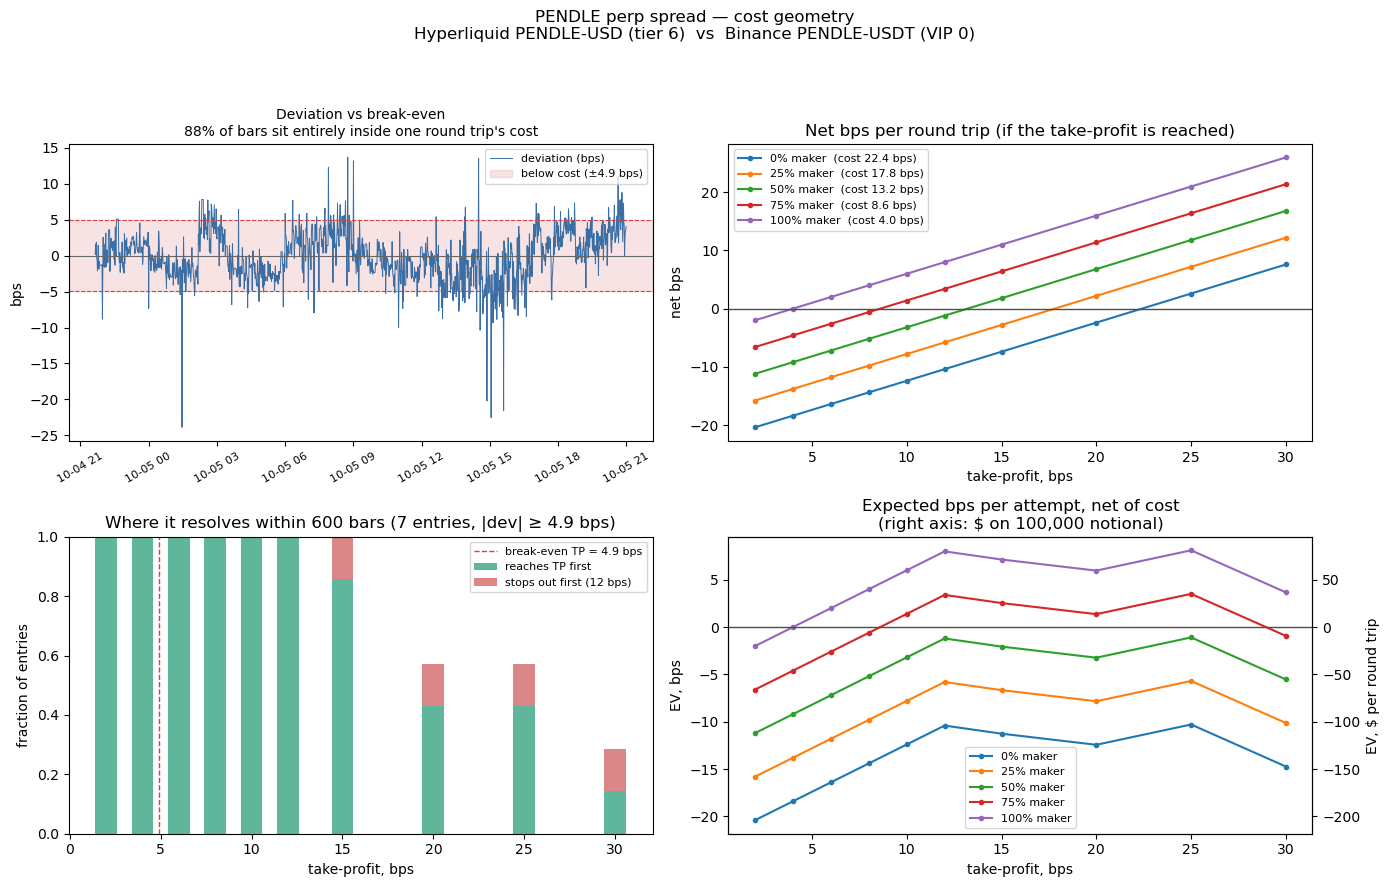

In [10]:
from spread_cost import plot_pnl, cost_breakdown

ref        = (df.hl_mid + df.bin_mid) / 2
spread_bps = (df.hl_mid - df.bin_mid) / ref * 1e4

fig, res = plot_pnl(spread_bps[-2_000:], taker=0.05, maker=0.95,
                    stop_bps=12, horizon_bars=600)   # 600 bars = 60s at 100ms

In [11]:
df.head()

,bin_mid,bin_bid,ask,bid_size_bin,ask_size_bin,imbalance_bin,microprice_bin,hl_mid,hl_bid,bid_size_hl,ask_size_hl,imbalance_hl,microprice_hl,microprice_diff,mid_diff,reference_mid,mid_diff_bps
datetime,,,,,,,,,,,,,,,,,
2026-09-29 03:16:00+00:00,86.2415,86.241,86.242,62.57,44.03,0.173921,86.241587,86.2475,86.247,2.25,175.92,-0.974743,86.247013,0.005426,0.0060,86.24450,0.695697
2026-09-29 03:17:00+00:00,86.3175,86.317,86.318,32.95,73.79,-0.382612,86.317309,86.3430,86.338,3.05,4.63,-0.205729,86.341971,0.024663,0.0255,86.33025,2.953773
2026-09-29 03:18:00+00:00,86.3035,86.303,86.304,141.78,1.01,0.985853,86.303993,86.2965,86.296,146.59,107.44,0.154116,86.296577,-0.007416,-0.0070,86.30000,-0.811124
2026-09-29 03:19:00+00:00,86.4245,86.424,86.425,33.54,25.10,0.143929,86.424572,86.4625,86.462,0.13,722.38,-0.999640,86.462000,0.037428,0.0380,86.44350,4.395935
2026-09-29 03:20:00+00:00,86.5165,86.516,86.517,30.00,41.20,-0.157303,86.516421,86.5175,86.517,243.10,494.08,-0.340460,86.517330,0.000908,0.0010,86.51700,0.115584


## Markov-Switching Latent Fair-Value Model

Start with the observed price decomposition:

$$
p_t = m_t + s_t + \epsilon_t
$$

where:

- $p_t$ = observed market price
- $m_t$ = latent efficient / fair price
- $s_t$ = temporary, predictable microstructure distortion
- $\epsilon_t$ = residual observation noise

### Efficient-price process

Model the latent efficient price as a random walk:

$$
m_t = m_{t-1} + \eta_t
$$

where $\eta_t$ represents innovations to the true efficient price.

### Microstructure distortion

Let the temporary distortion depend on both its previous value and current market-microstructure information:

$$
s_t
=
\rho_{z_t}s_{t-1}
+
\beta_{z_t}^{\top}x_t
+
\nu_t
$$

where:

- $z_t$ = latent market regime
- $\rho_{z_t}$ = persistence of temporary price distortion in regime $z_t$
- $\beta_{z_t}$ = regime-dependent weights on market-microstructure variables
- $x_t$ = vector of observable order-book / order-flow features
- $\nu_t$ = innovation to the temporary distortion

A simple initial feature vector could be:

$$
x_t =
\begin{bmatrix}
\text{microprice} - \text{midprice} \\
\text{order-flow imbalance} \\
\text{trade imbalance} \\
\text{bid-ask spread} \\
\text{depth imbalance}
\end{bmatrix}
$$

### Markov regime process

Assume the latent regime follows a Markov process:

$$
z_t \sim \operatorname{Markov}(P)
$$

where:

$$
P_{ij}
=
P(z_t = j \mid z_{t-1} = i)
$$

Possible regimes may correspond to states such as:

1. Balanced / normal market
2. Sustained buy pressure
3. Sustained sell pressure
4. Low-liquidity / stressed market

The regimes do not necessarily need to be manually labelled beforehand; they can be inferred statistically and interpreted afterwards.

### Fair-value estimate

The model produces an estimate of the current temporary distortion:

$$
\hat{s}_t
=
E[s_t \mid \mathcal{F}_t]
$$

and therefore the estimated latent efficient price is:

$$
\boxed{
\hat{m}_t = p_t - \hat{s}_t
}
$$

The purpose of the model is therefore to use observable microstructure information to separate temporary price pressure from movements in the underlying efficient price.

### Research progression

A natural progression for the research is:

1. **Midprice benchmark**
2. **Microprice benchmark**
3. **Linear microstructure fair-value model**
4. **Regime-dependent / Markov model**
5. **Full Markov-switching state-space model**

Each increase in complexity should only be retained if it improves out-of-sample estimates of the latent fair price or subsequent price movement.

In [13]:
import fv_models as fv
importlib.reload(fv)        # so edits to the module take effect
 
f = fv.build_features(df, basis_window=120, vol_window=60)
print(f.shape)
f.tail(3)

ModuleNotFoundError: No module named 'fv_models'